# Analyse exploratoire des données — Adult Income (UCI)

**Objectif du dataset :** prédire si le revenu annuel d'un individu dépasse
50 000 \$ (`>50K`) ou non (`<=50K`) à partir de caractéristiques
socio-démographiques (recensement US de 1994).

Ce notebook réalise une **EDA complète** en s'appuyant sur le module
`adult_income.eda.EDAAnalyzer`. Chaque section comporte :

> ⚠️ Bonne pratique : l'EDA se fait idéalement sur le **jeu d'entraînement
> uniquement**, pour ne pas « espionner » le test set (data leakage).
> Ici on explore l'ensemble complet pour décrire la donnée, mais on garde ce
> principe en tête au moment de modéliser.

## 0. Préparation de l'environnement

In [1]:
# Recharge automatique des modules src/ modifiés sans restart du kernel
%load_ext autoreload
%autoreload 2

# Permet d'importer le package src/ depuis le dossier notebooks/
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from adult_income import (
    DataLoader,
    EDAAnalyzer,
    CATEGORICAL_FEATURES,
    NUMERICAL_FEATURES,
    TARGET,
    POSITIVE_CLASS,
    NEGATIVE_CLASS,
)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

print("Imports OK")

Imports OK


## 1. Chargement des données

In [2]:
loader = DataLoader(test_size=0.2, random_state=42)
X, y = loader.load()

eda = EDAAnalyzer(X, y)
df = eda.df  # X + colonne cible 'income', pratique pour les croisements

print(f"Observations : {X.shape[0]:,}")
print(f"Features     : {X.shape[1]}")
df.head()

Observations : 48,842
Features     : 14


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K



On a donc 48842 observations, ce qui est assez conséquent et qui nous évite les problématiques liées à des datasets de taille réduite.
Concernant le nombre de features qui est de 14, il n'est pas trop important (nb features > nb data) ce qui nous évite aussi certaines problématiques liées à la modélisation dans des datasets trop complexes (overfitting notamment) et donc d'avoir à procéder à de la réduction de dimensions.

En revanche, particularité du dataset, les données manquantes d'une partie du dataset semblent être désignées avec des "?" (et pas des NaN), tandis que la suite du dataset (à partir de 32565) contient des NaN normaux. Pour éviter de les gérer séparément alors que "?" et NaN veulent dire la même chose, nous avons fait le choix de transformer les "?" en NaN dès le load.

De plus, les modalités de la cible se terminent par un point (`<=50K.` et `>50K.`). Nous les supprimons également dès le load pour éviter des potentielles erreurs.

In [3]:
df[df.eq('?').any(axis=1)]

,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income


## 2. Aperçu global & types de colonnes

In [4]:
print("=== Dimensions ===")
print("sans target :", eda.shape())
print("avec target : ", df.shape)

print("\n=== Types & mémoire ===")
df.info()

=== Dimensions ===
sans target : (48842, 14)
avec target :  (48842, 15)

=== Types & mémoire ===
<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       46043 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      46033 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  47985 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [5]:
eda.variable_overview()

,Variable,Description,Rôle,Type pandas,Type ML,Nombre de modalités
0,age,Âge de l'individu,Variable explicative,int64,Numérique,
1,workclass,Type d'employeur ou statut professionnel,Variable explicative,str,Catégorielle,8
2,fnlwgt,Poids statistique attribué à l'individu dans l...,Variable explicative,int64,Numérique,
3,education,Niveau d'éducation sous forme catégorielle,Variable explicative,str,Catégorielle,16
4,education-num,Niveau d'éducation sous forme numérique,Variable explicative,int64,Numérique,
5,marital-status,Statut marital de l'individu,Variable explicative,str,Catégorielle,7
6,occupation,Profession exercée,Variable explicative,str,Catégorielle,14
7,relationship,Lien familial ou statut dans le ménage,Variable explicative,str,Catégorielle,6
8,race,Catégorie ethnique déclarée,Variable explicative,str,Catégorielle,5
9,sex,Sexe de l'individu,Variable explicative,str,Catégorielle,2


**Observations**
Le jeu de données contient 15 variables : 14 variables explicatives et une variable cible, `income`.

Les variables explicatives sont de deux types : numériques et catégorielles. Les variables numériques décrivent par exemple l’âge, le nombre d’années d’éducation, les gains en capital ou le nombre d’heures travaillées par semaine. Les variables catégorielles décrivent notamment la situation professionnelle, le niveau d’éducation, le statut marital, la profession, le sexe ou le pays d’origine.

La variable cible `income` est une variable catégorielle binaire indiquant si le revenu annuel est inférieur ou égal à 50K ou supérieur à 50K. On travaille donc sur un problème de **classification**

Cette distinction est importante car les traitements appliqués ne seront pas les mêmes : les variables numériques pourront être standardisées, tandis que les variables catégorielles devront être encodées.

In [6]:
# Lignes strictement dupliquées (peuvent biaiser entraînement et CV)
n_dup = df.duplicated().sum()
print(f"Lignes dupliquées : {n_dup} ({n_dup / len(df) * 100:.2f} %)")

Lignes dupliquées : 52 (0.11 %)


On observe qu'il y a très peu de lignes strictement dupliquées, il y a donc peut d'intérêt à les traiter. De plus, ce ne sont pas forcément des doublons, car le dataset correspond à une enquête sans identifiant unique, donc avec un peu de chance, deux personnes peuvent avoir les mêmes caractéristiques selon l'enquête.

## 3. Variable cible & déséquilibre de classes

,count,pct
income,,
<=50K,37155,76.071823
>50K,11687,23.928177


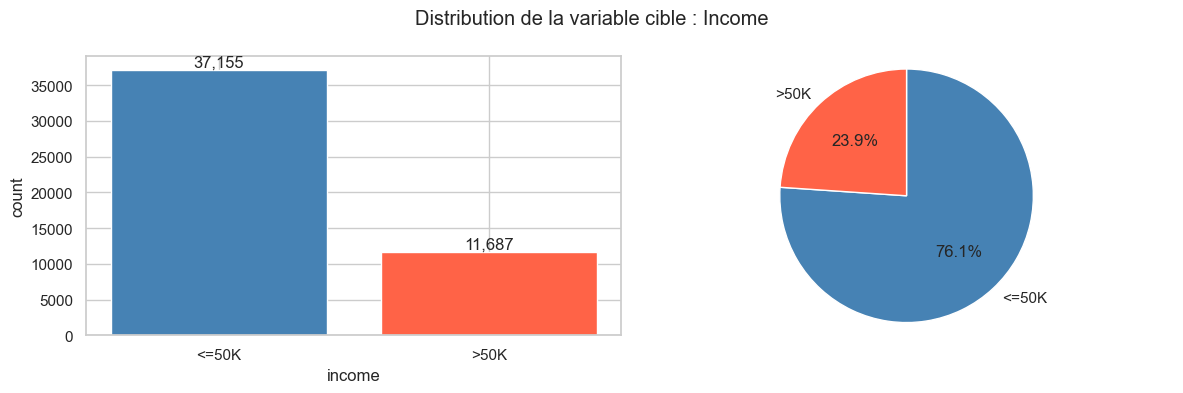

In [7]:
display(eda.class_balance())
eda.plot_class_balance()
plt.show()


La classe positive `>50K` est minoritaire (~24 %). Le dataset est donc déséquilibré (ratio ≈ 1:3).
Conséquences pour la modélisation :
  - L'accuracy seule n'est pas une bonne métrique pour ce jeu de données (un modèle prédisant toujours `<=50K`
    atteint ~76 %). Le déséquilibre restant modéré, on pourra utiliser des métriques telles que ROC-AUC, PR-AUC (souvent plus adapté en cas de déséquilibre), F1, precision/recall sur la classe positive.
  - Envisager `class_weight="balanced"`, un ré-échantillonnage, ou un ajustement
    du seuil de décision.
  - Stratifier le split train/test (déjà fait dans `DataLoader.split`) et la
    cross-validation pour préserver ce ratio.

## 4. Valeurs manquantes

Occurrences de '?' par colonne :
Aucune

NaN détectés par EDAAnalyzer.missing_values() :


,count,pct
occupation,2809,5.751198
workclass,2799,5.730724
native-country,857,1.754637


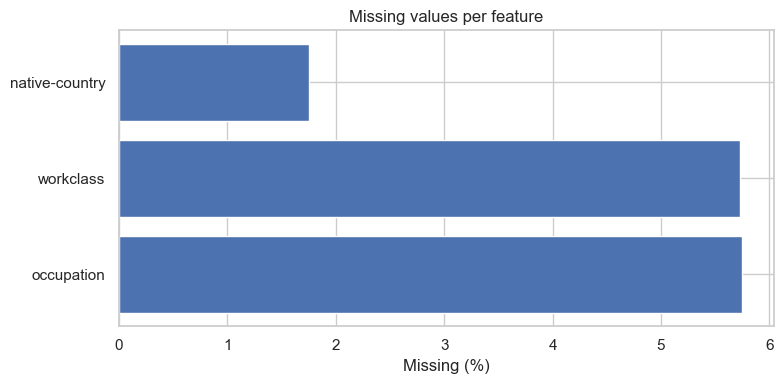

In [8]:
# Le dataset Adult code certains manquants par '?' plutôt que NaN.
q_marks = (X.astype("object") == "?").sum()
q_marks = q_marks[q_marks > 0]
print("Occurrences de '?' par colonne :")
print(q_marks if not q_marks.empty else "Aucune")

print("\nNaN détectés par EDAAnalyzer.missing_values() :")
display(eda.missing_values())

eda.plot_missing_values()
plt.show()

Les valeurs manquantes concernent uniquement certaines variables catégorielles : `occupation`, `workclass` et `native_country`. 
Comme le pourcentage de valeurs manquantes reste limité, nous conservons ces variables et nous les traiterons par imputation lors du prétraitement.

## 5. Analyse univariée

### 5.1. Variables numériques

On étudie maintenant les distributions des variables numériques.  
Cela permet d’identifier les ordres de grandeur, les asymétries, les valeurs extrêmes et les éventuelles différences d’échelle.

In [9]:
eda.numerical_stats()

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education-num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital-gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital-loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours-per-week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0



A part pour les feature capital-gain et capital-loss les moyennes et médianes sont très proches. Pour ces 2 features cela montre une distribution plutot asymétrique vers le haut (Tout le monde a zéro sauf quelques lignes avec des valeurs "importantes")

On peut observer des valeurs potentiellement abberantes pour la feature hours-per-weeks avec 1h et 99h, aussi la valeur max de capital gain est également très éloignée de la moyenne 99999 contre 1080. Ce sentiment est renforcé par la différence importante entre la moyenne et l'écart type pour ces 2 features.


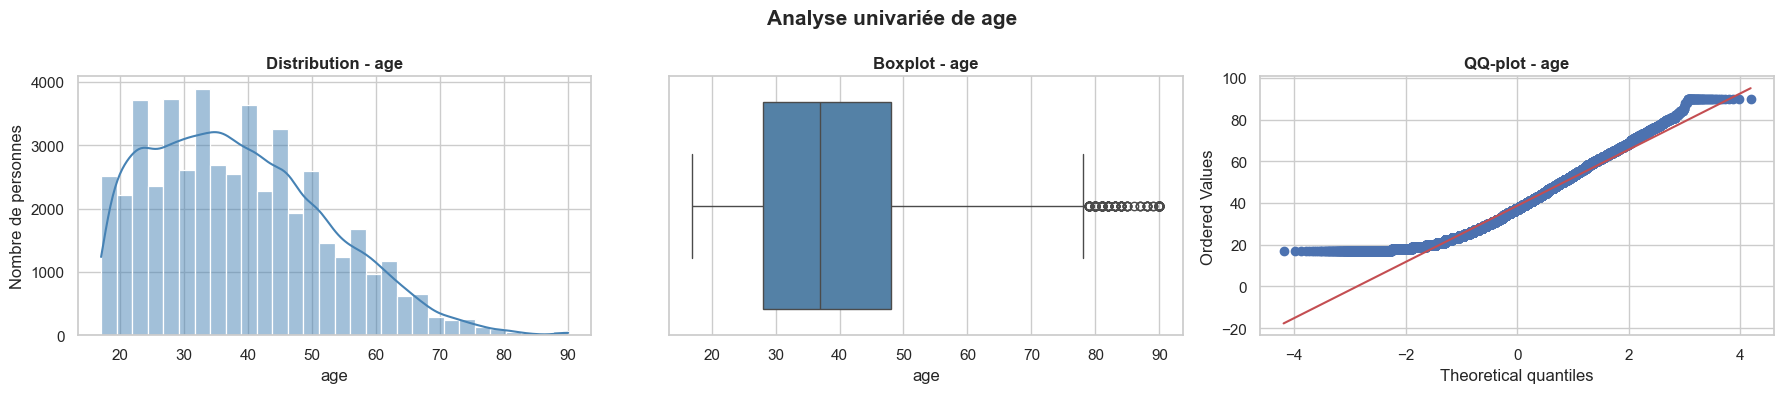

age : skewness = 0.56 | kurtosis = -0.18


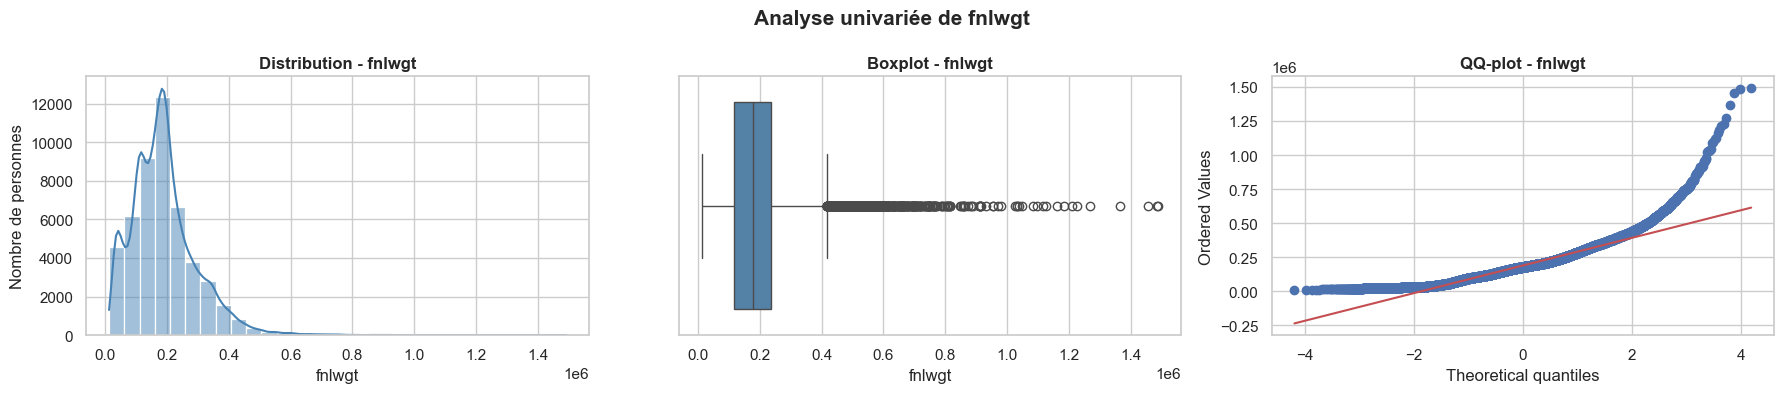

fnlwgt : skewness = 1.44 | kurtosis = 6.06


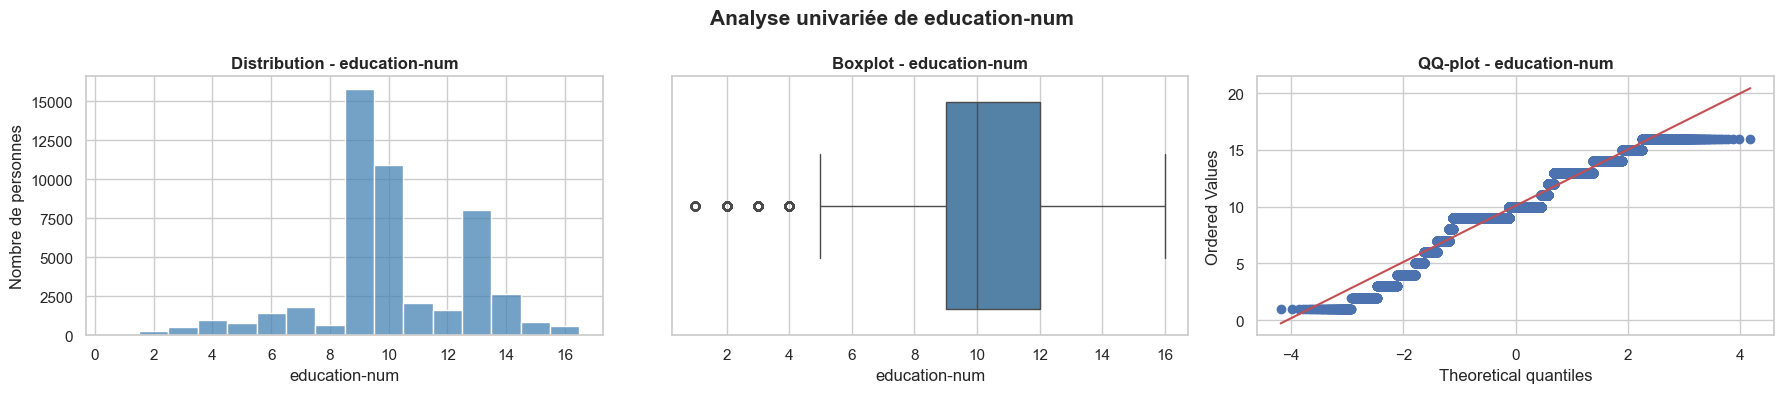

education-num : skewness = -0.32 | kurtosis = 0.63


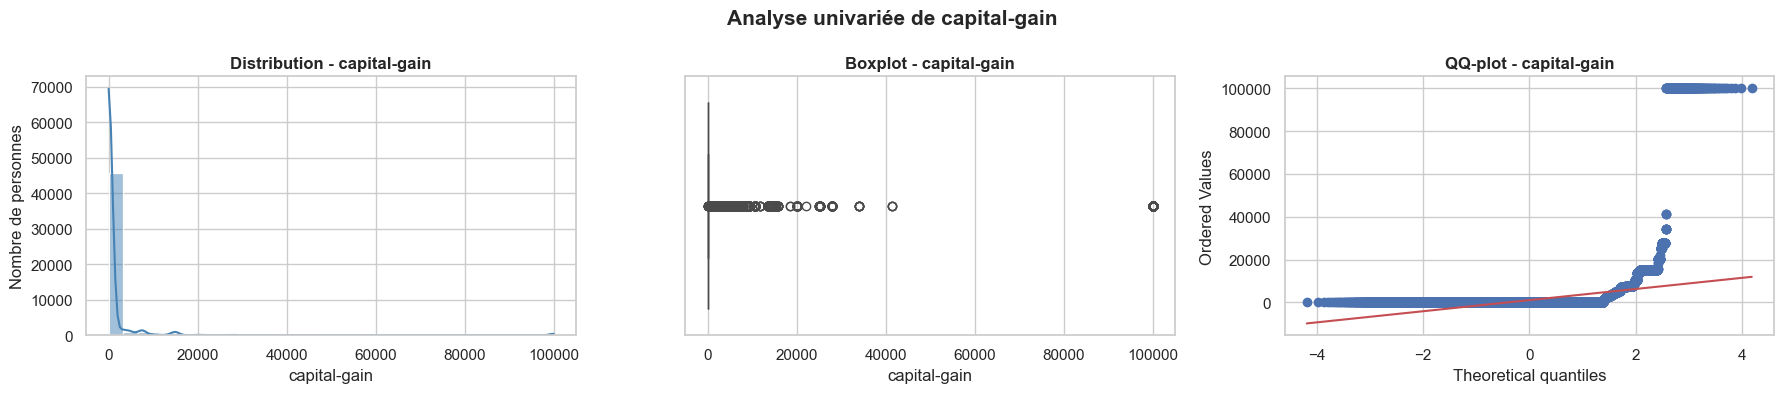

capital-gain : skewness = 11.89 | kurtosis = 152.69


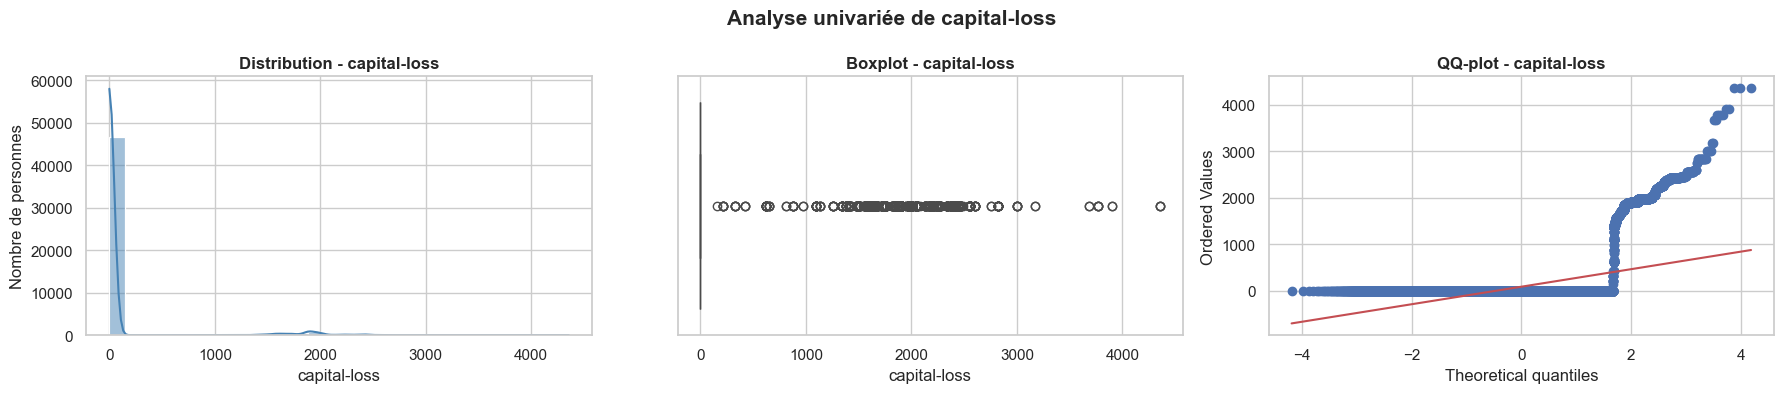

capital-loss : skewness = 4.57 | kurtosis = 20.01


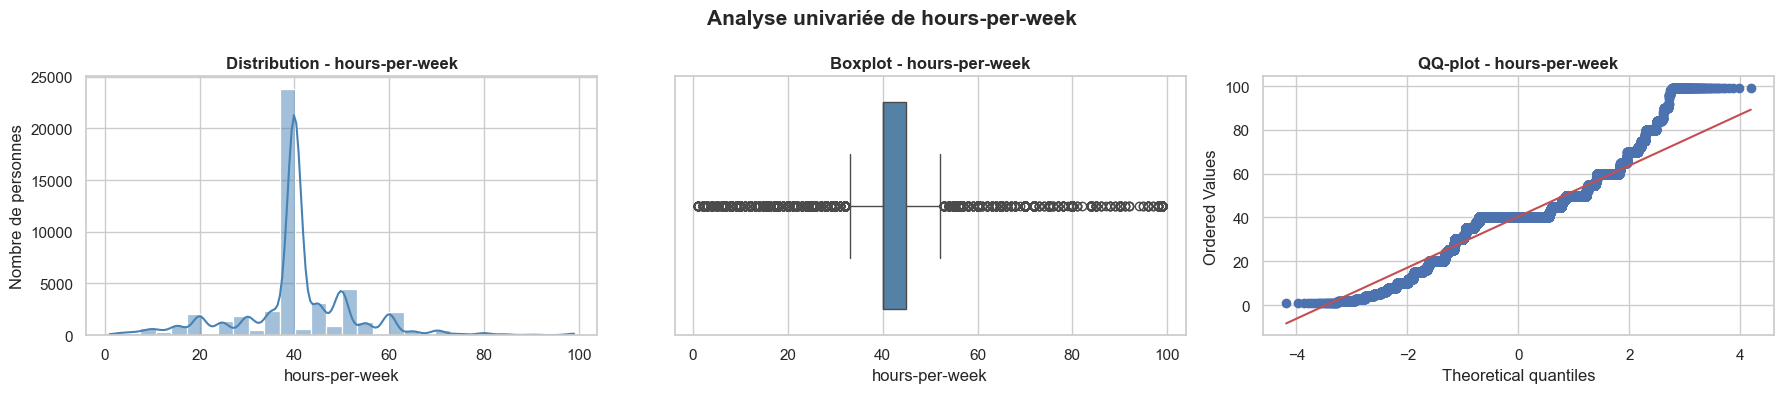

hours-per-week : skewness = 0.24 | kurtosis = 2.95


In [10]:
for i in NUMERICAL_FEATURES:
    eda.plot_numeric_diagnostics(i)
    plt.show()
    print(f"{i} : skewness = {eda.df[i].skew():.2f} | "f"kurtosis = {eda.df[i].kurt():.2f}")

**Observations**

Les variables numériques présentent des distributions assez différentes.

* **Âge** : la majorité des individus a entre 20 et 50 ans. La distribution est légèrement décalée vers les âges élevés. Les personnes les plus âgées apparaissent comme des valeurs aberrantes dans le boxplot, mais elles restent possibles (pas d'âges négatifs ou trop élevés). D'ordinaire, l'age forme plutot une loi normale, mais étant donné que les personnes sondées ont au minimum 17, il manque une partie significative de la queue gauche de la loi normale, ce qui fait que le Q-Q plot n'annonce pas vraiment une potentielle loi normale.

* **Poids statistique d'un individu (`fnlwgt`)** : la distribution est assez asymétrique positivement (comme le montre la skewness), avec un certain nombre de valeurs aberrantes. Le kurtosis est également élevé, ce qui donne une distribution leptokurtique (étirée). Les valeurs élevées ne sont donc pas nécessairement des erreurs, cela signifie surtout qu'ils ont un poids statistique très important, et donc qu'ils sont plus représentatifs de la population que l'individu moyen. Cette variable est assez obscure en termes de signification, et également assez subjective.

* **Années d’éducation (`education_num`)** : cette variable est discrète et présente plusieurs valeurs fréquentes, notamment entre 9 et 12 années. La forme en escalier du QQ-plot est liée au faible nombre de valeurs possibles.

* **Gain en capital (`capital-gain`)** : le fait que la grande majorité des individus possède une valeur nulle donne une forme assez difficile à lire aux graphiques en question. Nous étudierons les valeurs non nulles ci-dessous. On observe également que la skewness de 11.89 indique une distribution fortement assymétrique positivement. Le kurtosis extrêmement élevé illustre bien ce qu'on voit dans le graphique : une distribution très étirée en forme de pointe.

* **Perte en capital (`capital-loss`)** : comme pour le gain en capital, la grande majorité des valeurs est nulle et les graphiques sont assez peu informatifs. Nous étudierons plus en détail cet aspect ci-dessous. Pour le kurtosis et la skewness, le raisonnement est le même que pour `capital-gain` en légèrement moins elevé.

* **Heures travaillées par semaine (`hours-per-week`)** : la distribution présente un pic très important autour de 40 heures par semaine. Certaines personnes déclarent travailler beaucoup moins ou beaucoup plus, ce qui explique les valeurs atypiques du boxplot.

Globalement, les variables numériques ne suivent pas une loi normale et présentent des échelles très différentes. Cependant, la normalité des variables n’est pas obligatoire pour les modèles utilisés dans ce projet.

Nous conservons donc toutes les observations et toutes les variables numériques pour le moment, en gardant en tête l'aspect assez particulier de la variable `fnlwgt`. Lors du prétraitement, les éventuelles valeurs manquantes seront remplacées par la médiane, puis les variables seront standardisées afin qu’elles aient des échelles comparables. **VOIR CE QUI A ETE FAIT DANS PRETRAITEMENT^**


#### 5.1.1. Analyse des variales capital-gain et capital-loss sans les valeurs nulles

In [11]:
print(eda.zero_proportion(["capital-gain", "capital-loss"]))

                    = 0       > 0
capital-gain  91.738668  8.261332
capital-loss  95.327792  4.672208


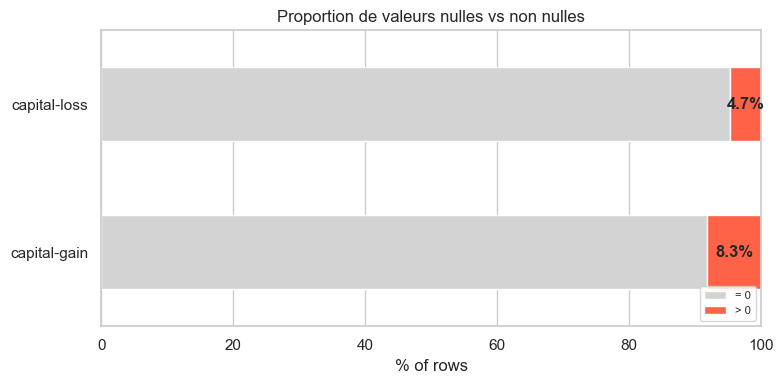

In [12]:
eda.plot_zero_proportion(["capital-gain", "capital-loss"]);

On constate bien que la proportion d'individus ayant un `capital-gain` ou un `capital-loss` > 0 est faible

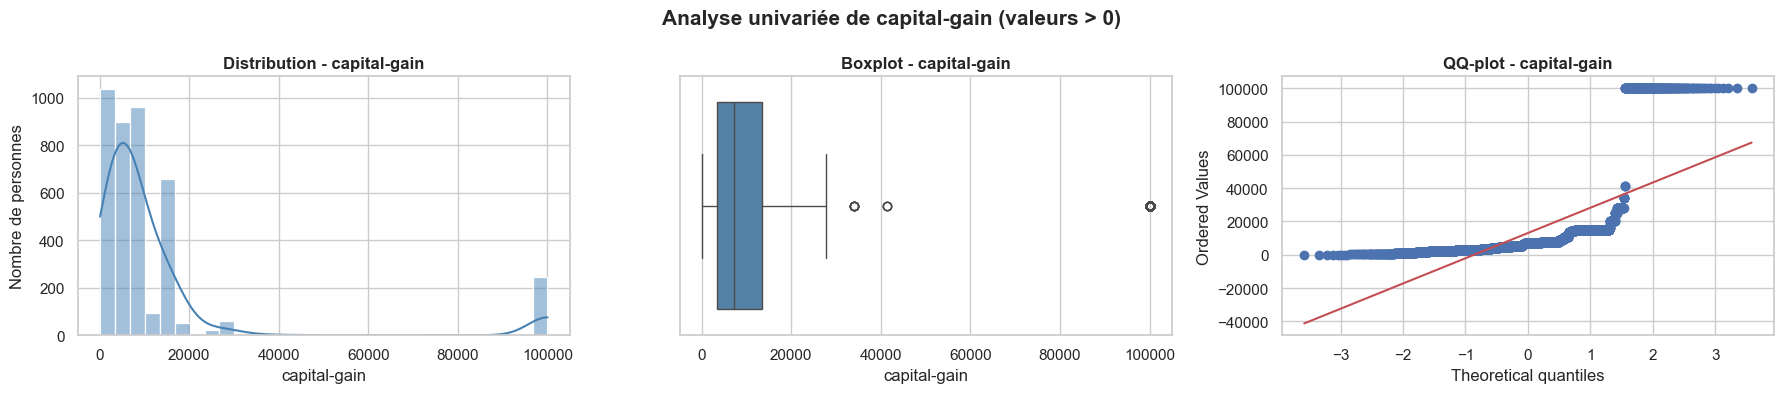

capital-gain (valeurs > 0) : skewness = 3.36 | kurtosis = 10.03


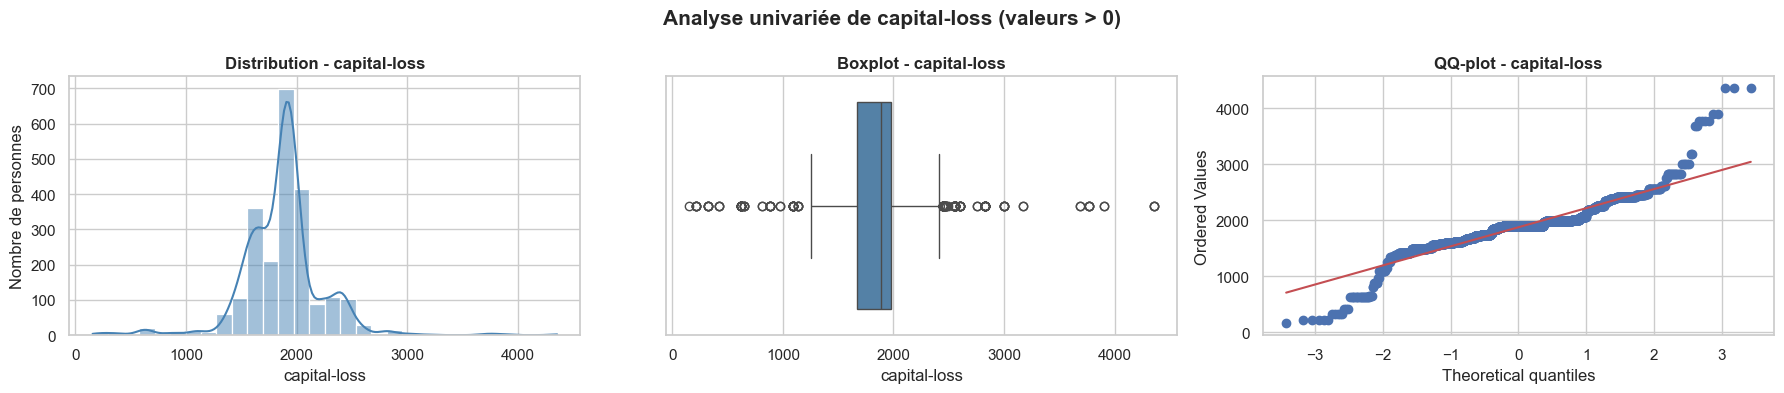

capital-loss (valeurs > 0) : skewness = 0.31 | kurtosis = 7.82


In [13]:
for i in ["capital-gain", "capital-loss"]:
    eda.plot_numeric_diagnostics(i, filter_positive=True)
    plt.show()

    # Quantification de l'asymétrie et de l'aplatissement (sur les valeurs > 0)
    nonzero = eda.df[i][eda.df[i] > 0]
    print(f"{i} (valeurs > 0) : skewness = {nonzero.skew():.2f} | "
          f"kurtosis = {nonzero.kurt():.2f}")

**Observations**

* **Gain en capital (`capital-gain`)** : on observe que la grande majorité des gens, parmis la minorité de personnes ayant un `capital-gain` > 0, on un gain en capital qui tourne aux alentours des 10000$ (dataset américain, donc on suppose que c'est des $). On observe aussi quelques valeurs aberrantes, notamment le maximum observé tout à l'heure de 99999. Pas de distribution particulière suivie ici.

* **Perte en capital (`capital-loss`)** : ici, les valeurs sont toujours très concentrées, cette fois autour de 1800/2000$ de perte. Le boxplot est moins biaisé qu'au dessus car il n'y a pas de valeurs aberrantes extrèmes. La distribution n'est pas normale mais est un peu plus équilibrée que celle de `capital-gain`.

Avec la considération des valeurs positives également, la skewness et le kurtosis des deux variables a considérablement diminué, mais `capital-gain` conserve une skewness elevée proportionnellement (rapport x3 environ) en comparaison au kurtosis (rapport x15 environ), ce qui est du à la présence d'outliers extrêmes.

On ne tire pas de conclusions particulières ici sur les données en termes de modélisation, mais il faudra peut-être réfléchir à gérer les valeurs aberrantes dans `capital-gain` (par exemple via normalisation, car les moyennes et écarts-type de `capital-gain` sont biaisés, tirés vers le haut par ces quelques valeurs extrêmes). Il pourrait être également possible de faire un encodage binaire pour `capital-loss` car étant donné que la distribution est assez concentrée, elle n'apporte pas beaucoup d'information.

### 5.2. Variables catégorielles

On analyse les variables catégorielles en étudiant leurs modalités et leurs effectifs.  
Cela permet d’identifier les catégories dominantes, les catégories rares et les variables ayant beaucoup de modalités.

In [ ]:
eda.categorical_stats() # rare : <1% par défaut

,n_unique,top,top_pct,n_rare,missing
feature,,,,,
workclass,8,Private,69.419762,2,2799
education,16,HS-grad,32.316449,2,0
marital-status,7,Married-civ-spouse,45.819172,1,0
occupation,14,Prof-specialty,12.636665,2,2809
relationship,6,Husband,40.366897,0,0
race,5,White,85.504279,2,0
sex,2,Male,66.848204,0,0
native-country,41,United-States,89.742435,39,857


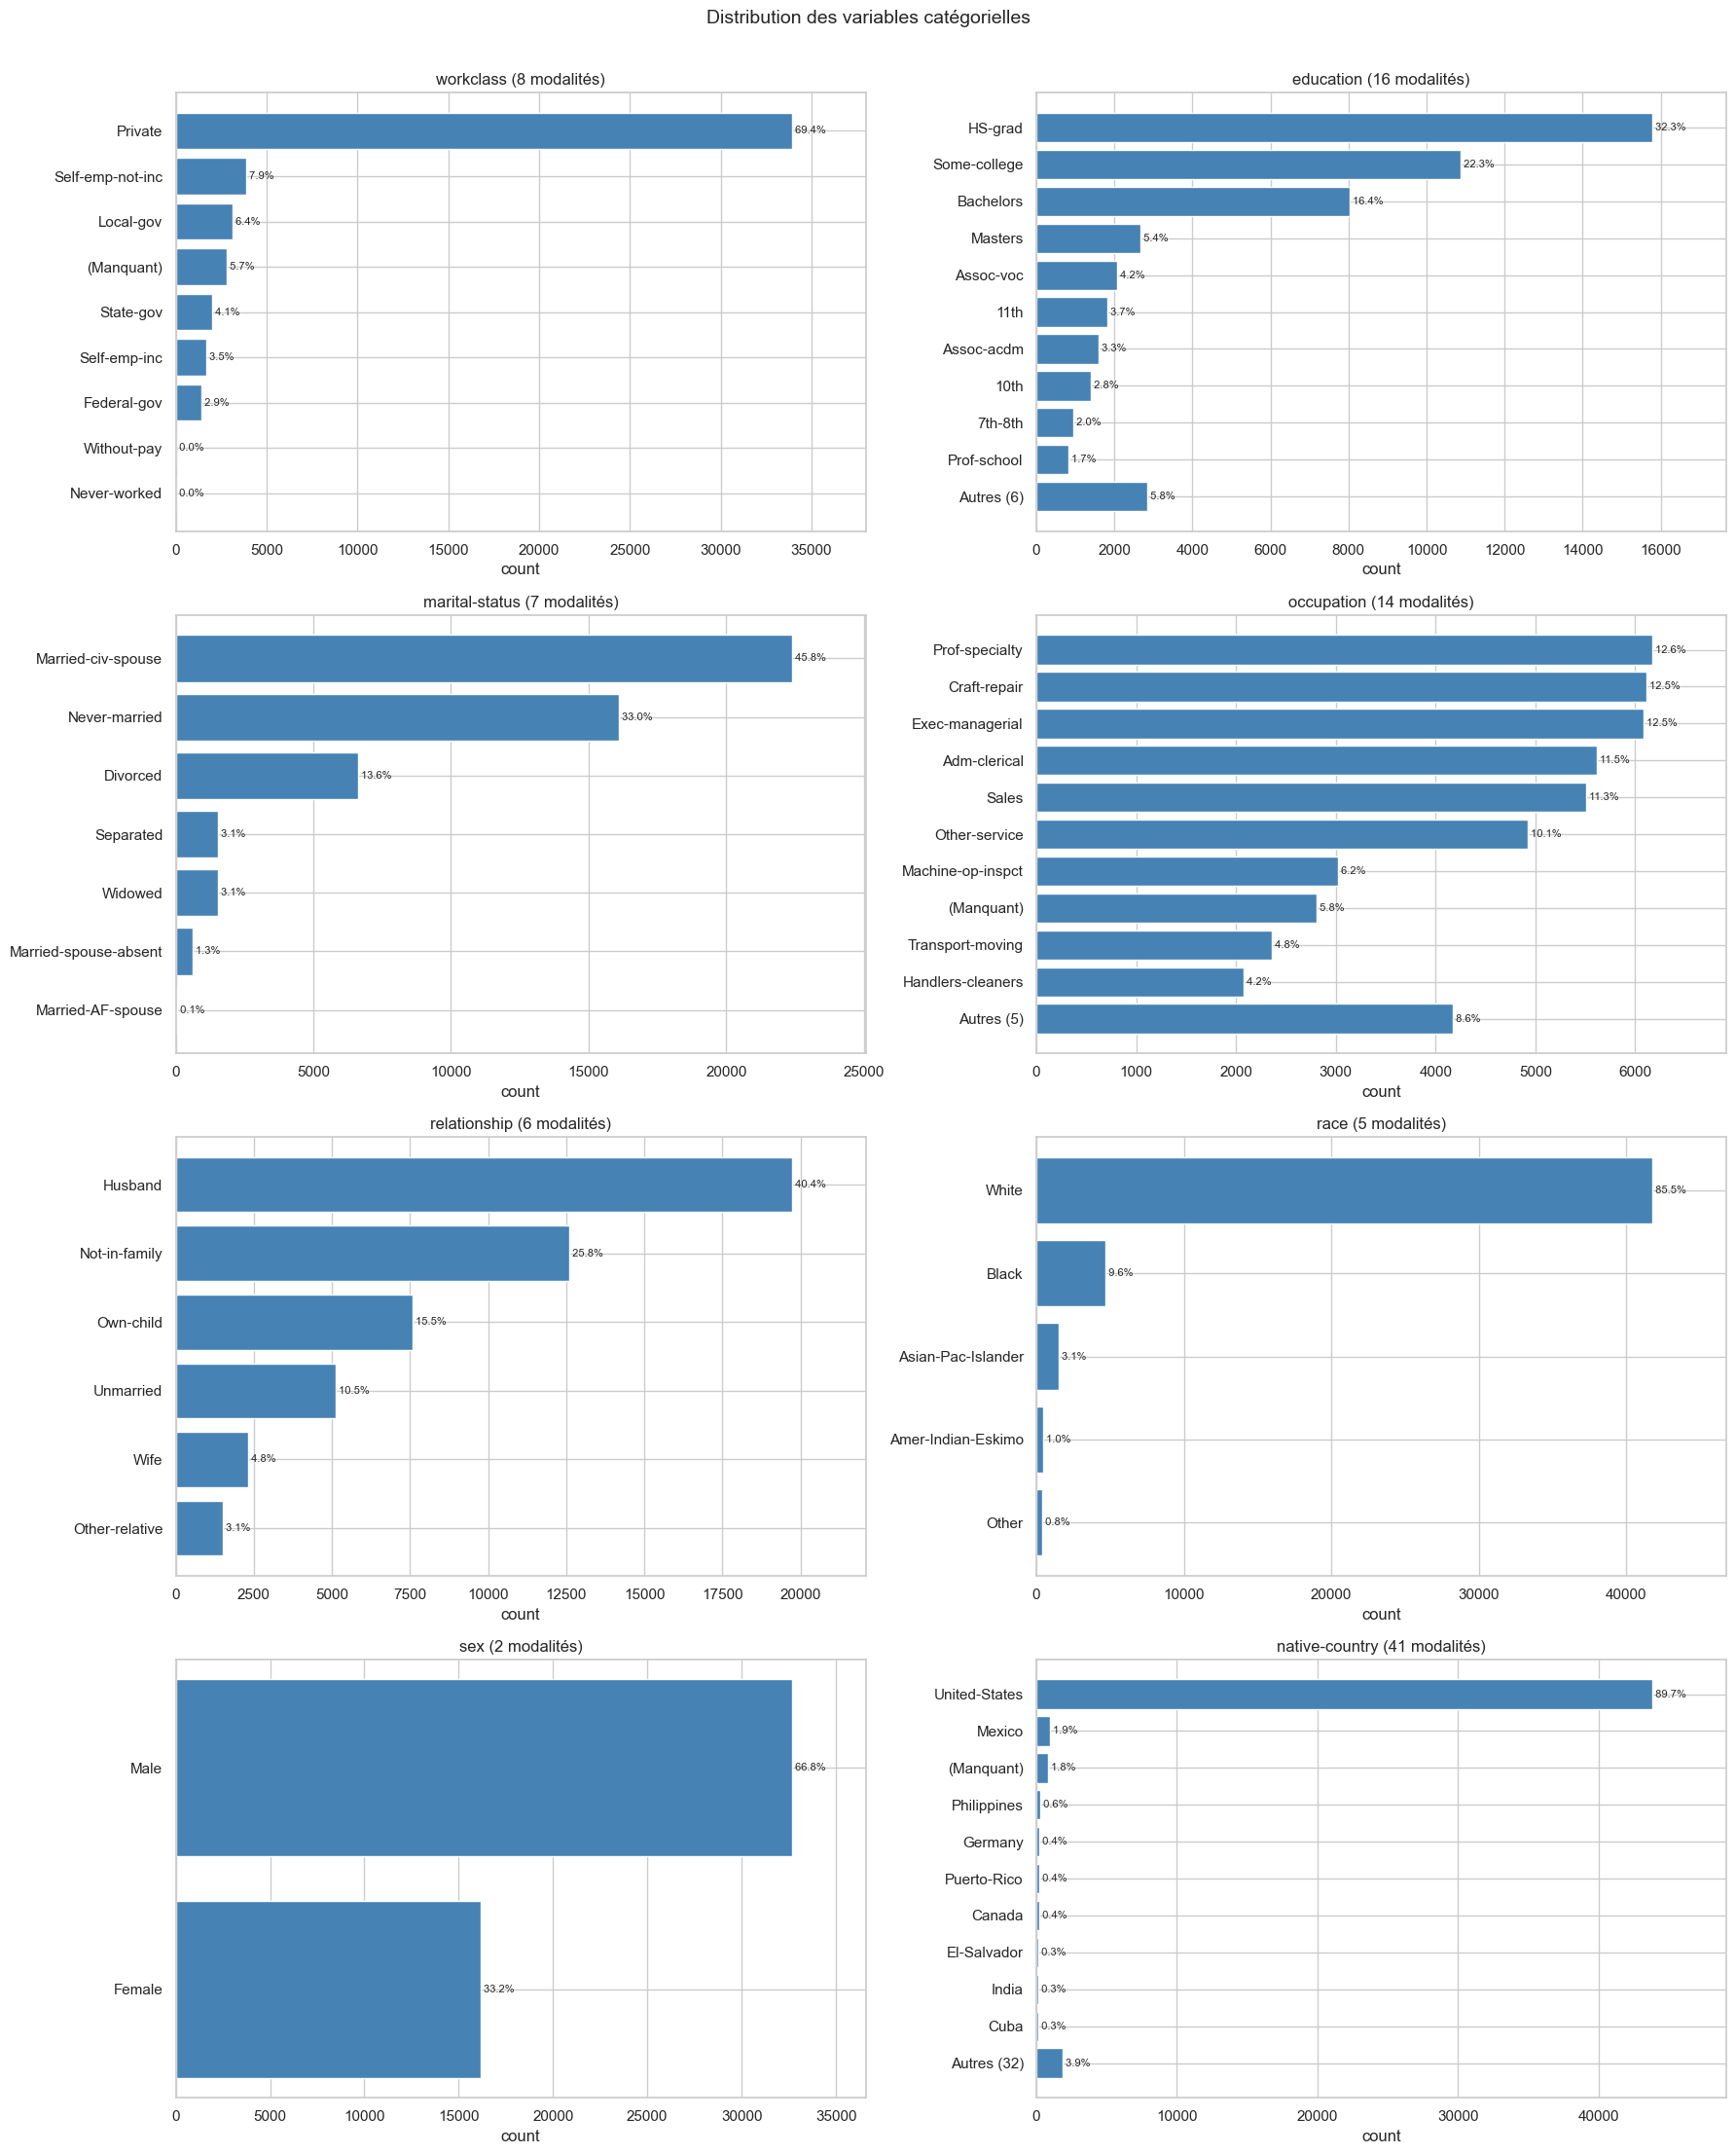

In [15]:
eda.plot_categorical_univariate(); plt.show()

In [16]:
print(eda.df["workclass"].value_counts())

workclass
Private             33906
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64


In [17]:
print(eda.df["native-country"].value_counts().head(5))

native-country
United-States    43832
Mexico             951
Philippines        295
Germany            206
Puerto-Rico        184
Name: count, dtype: int64


**Observations**

L’analyse des variables catégorielles met en évidence des catégories dominantes, des catégories rares et certaines variables possédant un nombre important de modalités.

* **`workclass`** : la catégorie `Private` est très largement majoritaire. Les catégories `Without-pay` et `Never-worked` sont très rares. La variable est assez fortement déséquilibrée.

* **`education`** : les modalités les plus fréquentes sont `HS-grad`, `Some-college` et `Bachelors`. Les autres niveaux d’éducation sont moins représentés. Cette variable possède un nombre assez important de modalités, mais reste relativement équilibrée.

* **`marital_status`** : les catégories `Married-civ-spouse` et `Never-married` sont dominantes, suivies par `Divorced`. Les situations comme `Married-spouse-absent` sont rares.

* **`occupation`** : plusieurs professions sont bien représentées, notamment `Prof-specialty`, `Craft-repair`, `Exec-managerial` et `Adm-clerical`. La répartition est plus équilibrée que pour les autres variables, même si certaines professions sont peu fréquentes. Cette variable contient un nombre assez important de modalités.

* **`relationship`** : les catégories `Husband`, `Not-in-family` et `Own-child` sont les plus représentées. Les modalités `Wife` et `Other-relative` sont plus rares.

* **`race`** : la catégorie `White` est très largement majoritaire. Les autres catégories, en particulier `Amer-Indian-Eskimo` et `Other`, sont peu représentées. Cette variable est donc fortement déséquilibrée.

* **`sex`** : les hommes sont nettement plus nombreux que les femmes dans le jeu de données.

* **`native_country`** : la grande majorité des individus vient des `United-States`. Les autres pays sont très peu représentés. Cette variable possède beaucoup de modalités, mais la plupart sont rares. Cette variable est la plus déséquilibrée du dataset (catégorielle). Il pourrait potentiellement être intéréssant de créer une modalité `Other` représentant les pays particulièrement sous représentés (par exemple < 100 individus) afin de réduire le nombre de modalités, en sachant que 39 modalités sur 41 ne sont présentes que <1% du temps.

Globalement, plusieurs variables catégorielles sont déséquilibrées, dont certaines présentent un fort déséquilibre (notamment `race`, `workclass` ou encore `native_country`). Les variables `education`, `occupation` et surtout `native_country` possèdent un nombre important de modalités (> 14).

Lors du prétraitement, les valeurs manquantes pourront par exemple être remplacées par la modalité la plus fréquente, en tout cas pour `native_country` et `workclass`. Pour `occupation` en revanche, il pourrait convenir de créer une modalité "unknown" car les modalités les plus fréquentes se talonnent de près, et donner 5.8% de valeurs en plus à une de ces modalités peut être néfaste pour la modélisation.

Nous pensons que les variables catégorielles dont le nombre de modalités dépasse 15 (`education` et `native_country`) pourraient être encodées d'une autre manière qu'un one-hot, car cela augmenterait trop la dimensionnalité. Nous pensons par exemple à du TargetEncoding ou encore du LabelEncoding. Les autres variables seront certaintement encodées à l'aide du one-hot encoding.

## 6. Analyse bivariée

### 6.1 Variables numériques et cible

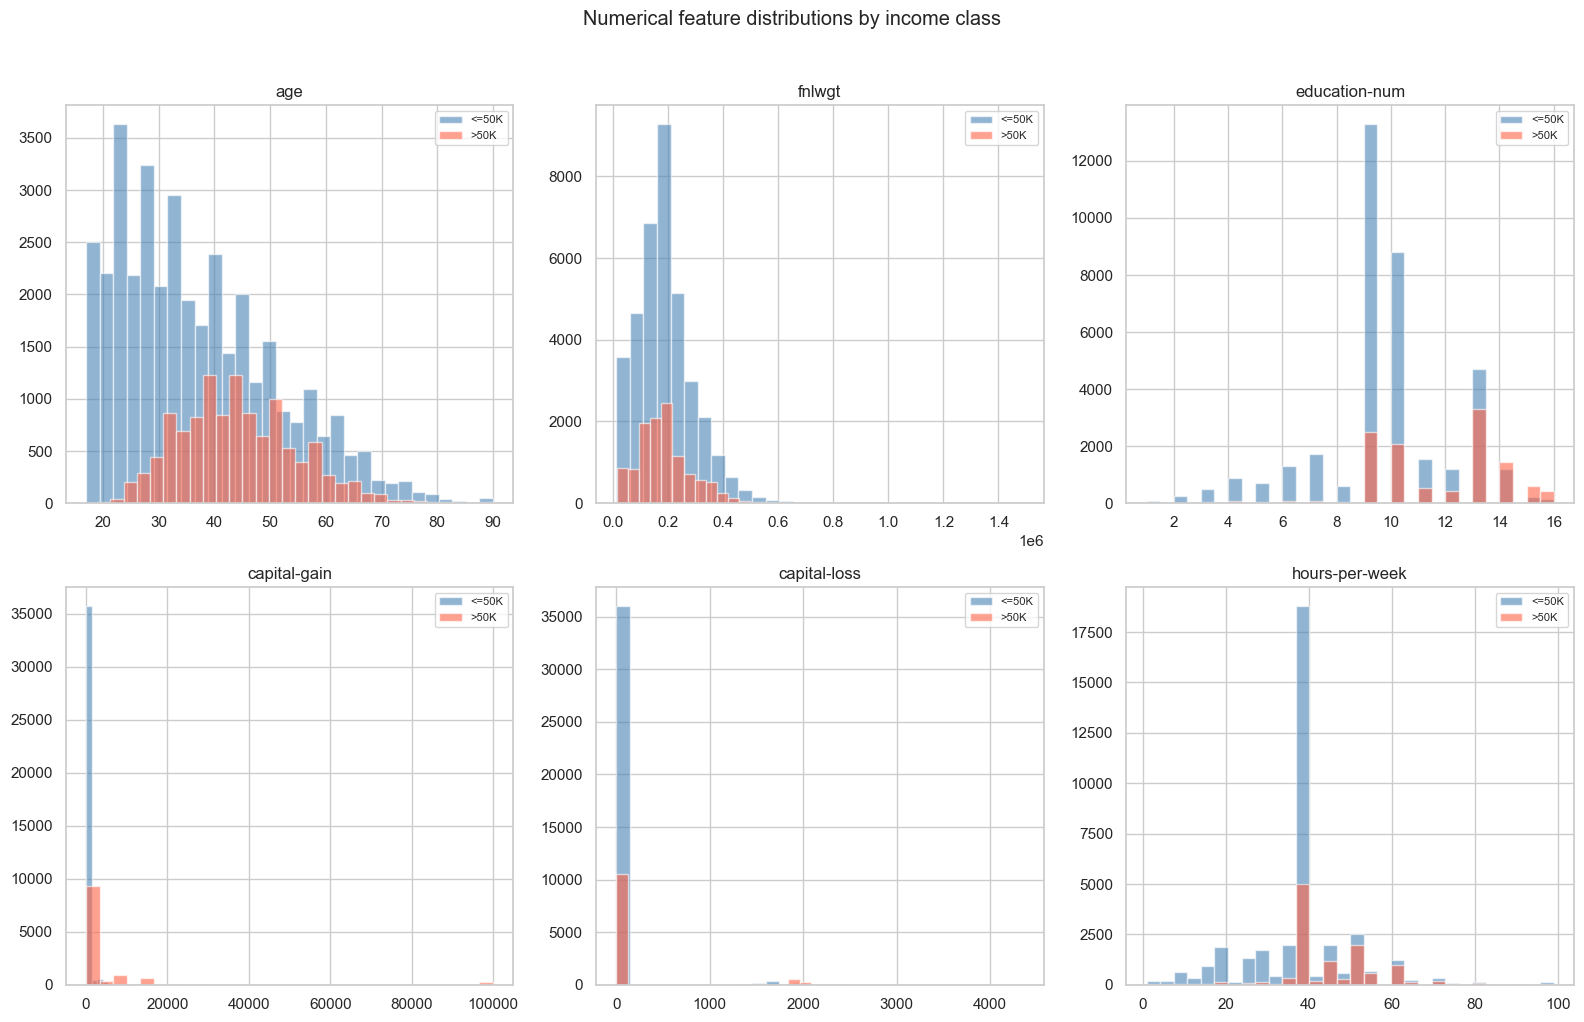

In [18]:
eda.plot_numerical_distributions()
plt.show()


3 variables séparent bien les classes : age, education-num et hours-per-week. Cela semble logique que les personnes plus agés, plus diplomés et qui travailent plus aient de meilleurs revenus.
Les variables capital-gain/loss ont une distributions concentrées vers 0, une transformation comme le log ou un encodage bianire pourrait etre envisagé.
fnlwgt représente le poids statistique attribué par le recensement américain. Il indique combien de personnes de la population sont représentées par cet individu. On ne voit pas trop comment cette feature pourrait etre utile au modèle => supression ?

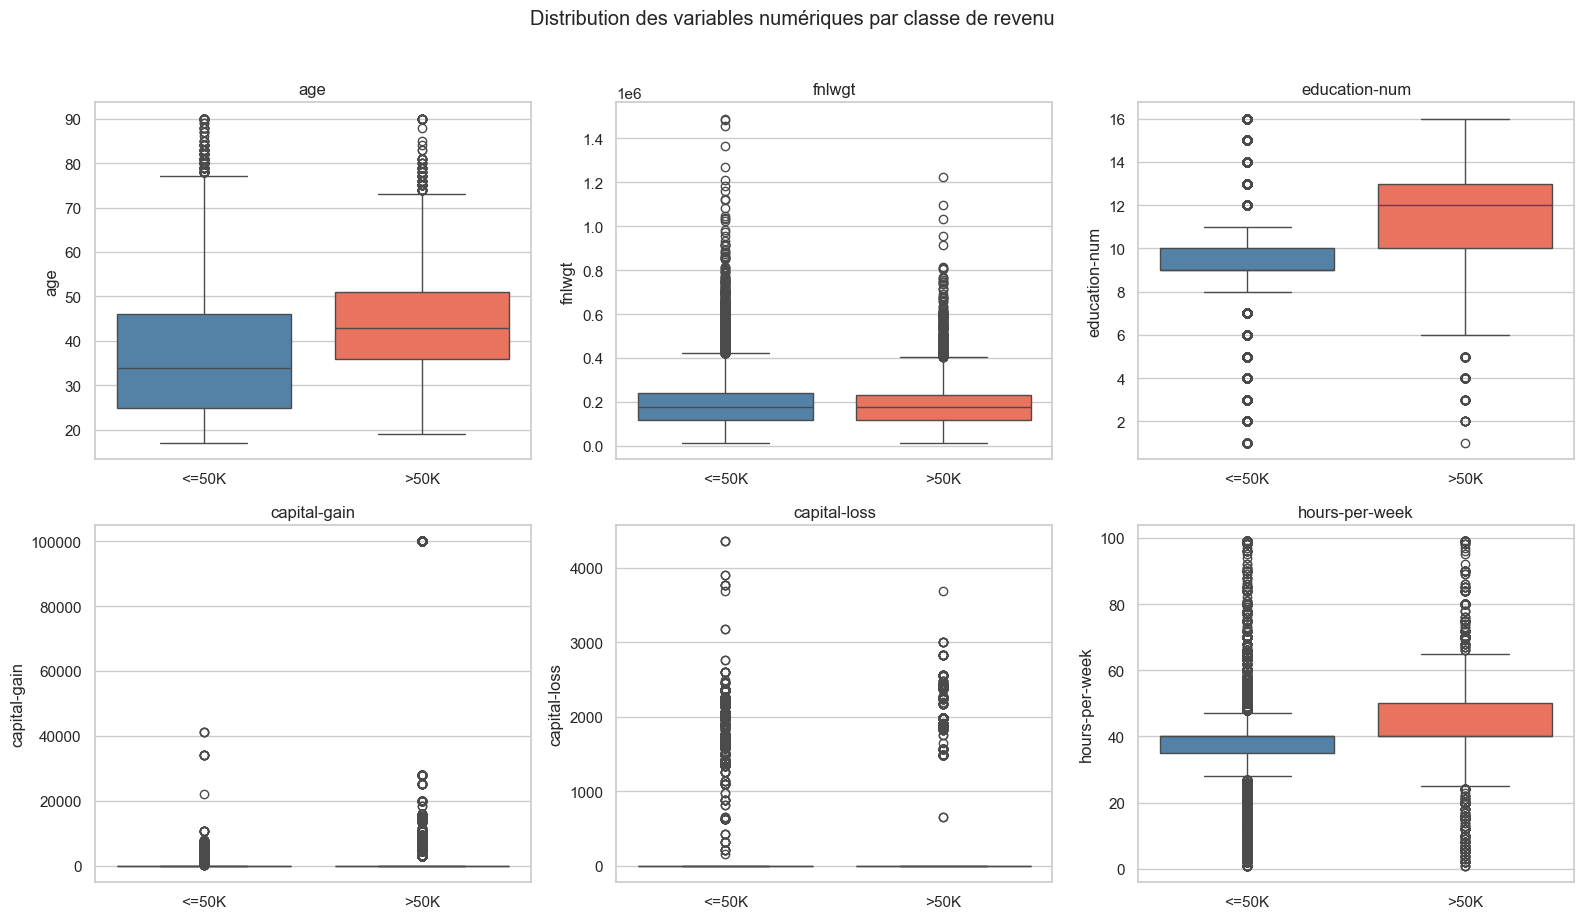

In [19]:
# Boxplots par classe : lecture directe du pouvoir discriminant + outliers
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, NUMERICAL_FEATURES):
    sns.boxplot(data=df, x=TARGET, y=col, ax=ax, hue=TARGET,
                palette={NEGATIVE_CLASS: "steelblue", POSITIVE_CLASS: "tomato"})
    ax.set_title(col)
    ax.set_xlabel("")
fig.suptitle("Distribution des variables numériques par classe de revenu", y=1.02)
fig.tight_layout()
plt.show()

Beaucoup d'outliers pour les 2 variables capital-gain/loss, on ne voit même pas la boite a moustache = logique avec le tableau précédent ou tout les quartiles valent 0.

On voit beaucoup d'outliers des 2 cotés de la boite a moustache pour la variable hours par week 

## 6. Quantification des valeurs extrêmes (règle IQR)

In [20]:
def iqr_outlier_rate(s: pd.Series) -> float:
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return ((s < low) | (s > high)).mean() * 100

rates = {c: iqr_outlier_rate(X[c]) for c in NUMERICAL_FEATURES}
pd.Series(rates, name="% outliers (IQR)").sort_values(ascending=False).to_frame()

,% outliers (IQR)
hours-per-week,27.631956
capital-gain,8.261332
capital-loss,4.672208
education-num,3.673068
fnlwgt,2.974899
age,0.442242



On retrouve un taux d'outliers très important. Il faudra faire un choix de transformation pour les variables capital. Une transformation peut etre envisagé pour hours per weeks également.

## 7. Corrélations entre variables numériques

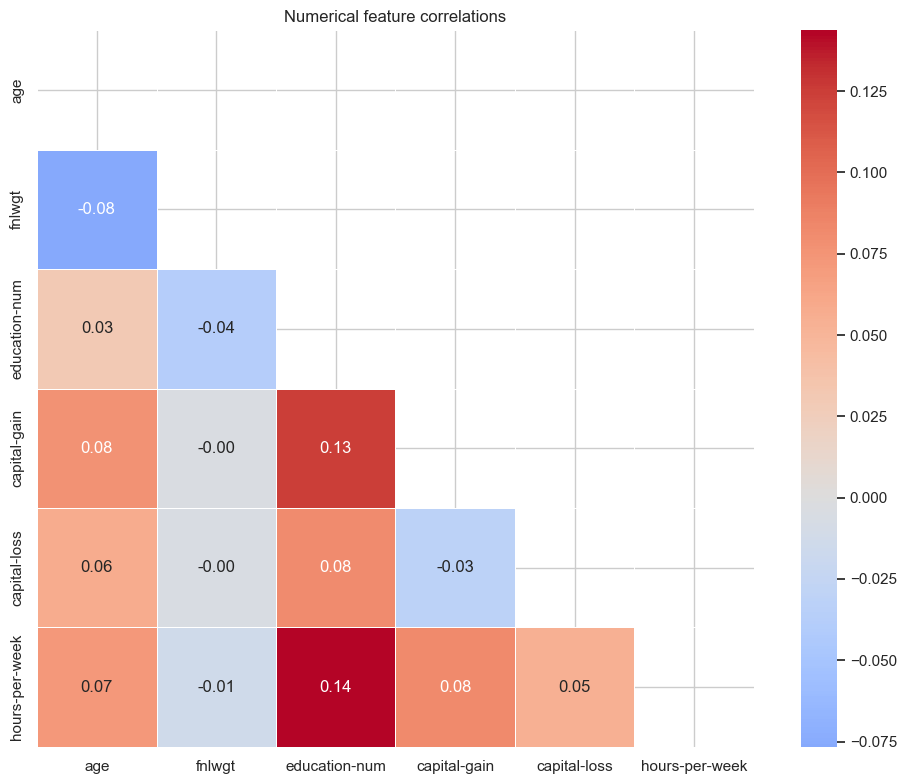

In [21]:
eda.plot_correlation_matrix()
plt.show()

Aucune corrélation élevé toutes les variables sont à conserver

## 8. Variables catégorielles

In [22]:
eda.categorical_stats()

,n_unique,top,top_pct,n_rare,missing
feature,,,,,
workclass,8,Private,69.419762,2,2799
education,16,HS-grad,32.316449,2,0
marital-status,7,Married-civ-spouse,45.819172,1,0
occupation,14,Prof-specialty,12.636665,2,2809
relationship,6,Husband,40.366897,0,0
race,5,White,85.504279,2,0
sex,2,Male,66.848204,0,0
native-country,41,United-States,89.742435,39,857



On voit que native-country compte 42 modalités, un encodage one-hot n'est donc pas une bonne idée au risque de faire exploser le nombre de colonnes. On peut utiliser la même logique pour occupation et education (16 et 15 modalités). => Utilisation d'un encodage par fréquence.
Top donne la modalité dominante, il faudra faire attention par la suite à si on découvre des modalités ultra dominante.

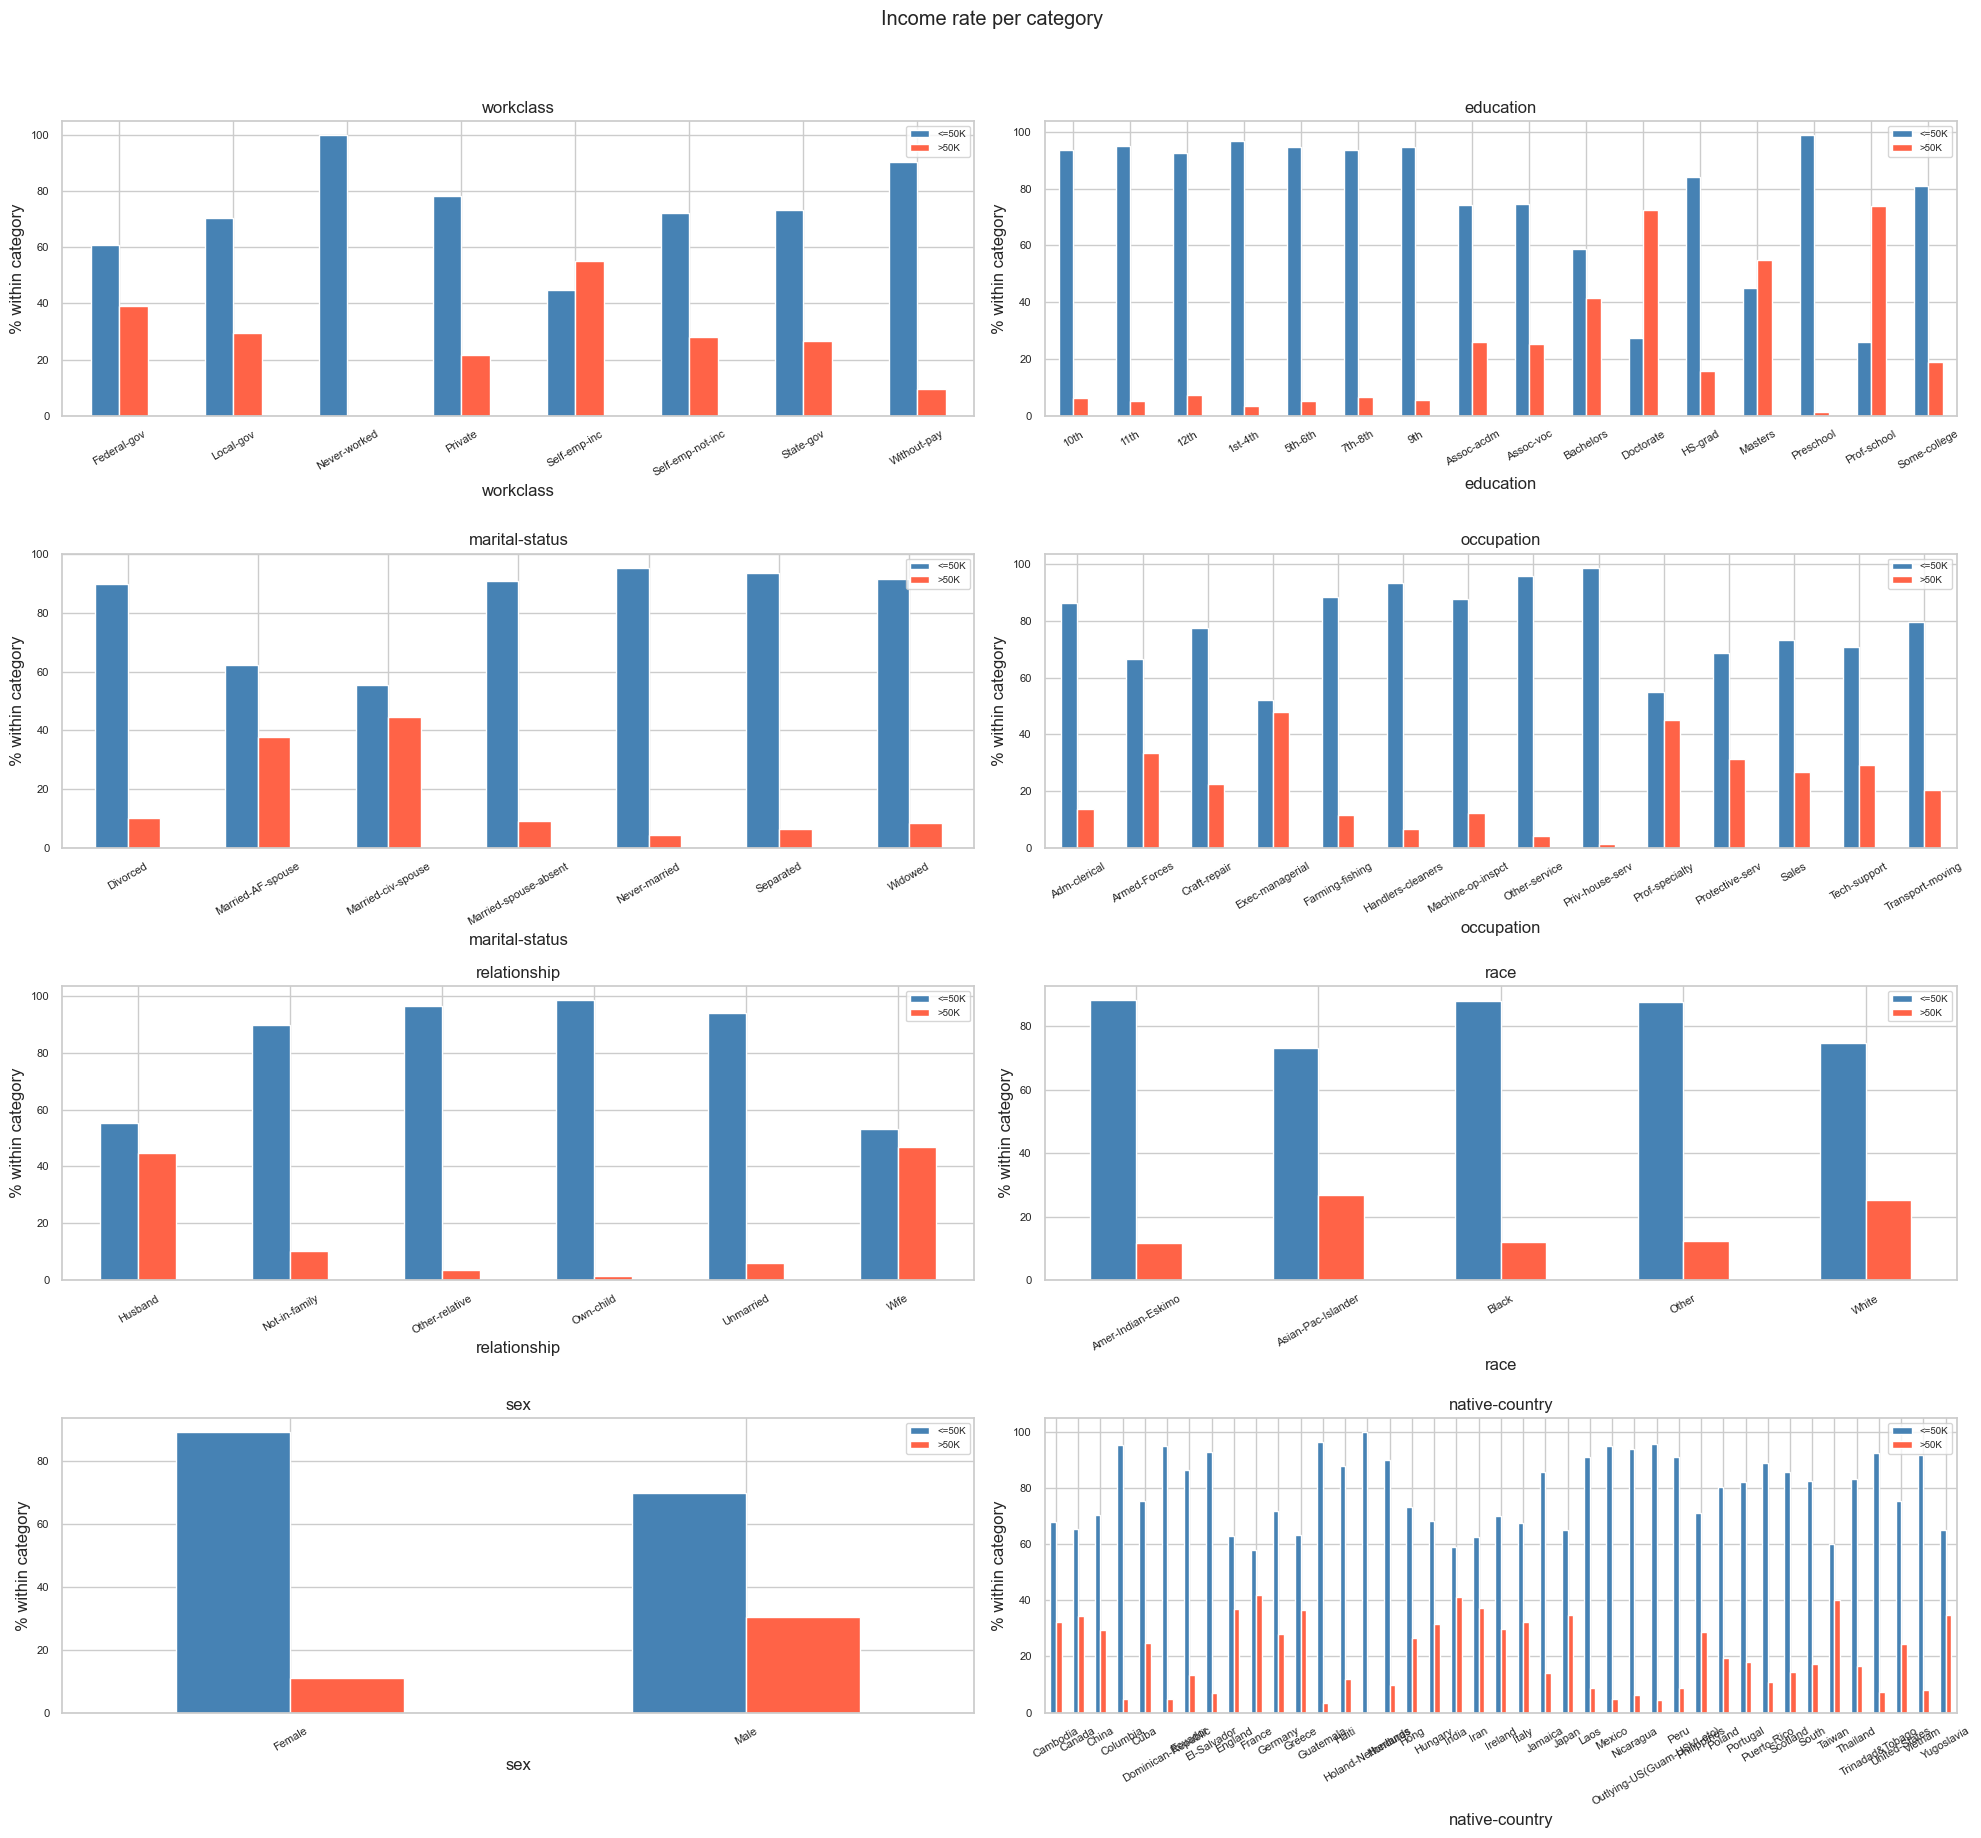

In [23]:
eda.plot_categorical_distributions()
plt.show()


Une barre rouge au dessus de la moyenne (24%) signifie que cette variable est un signal fort : 
 - marital-status = Married-civ-spouse
 - relationship = Husband/Wife
 - education = Doctorate/Prof-school/Masters
 - occupation = Exec-managerial/Prof-specialty

On remarque d'autre variable avec un taux très bas :
- marital-status = Never married
- relationship = Own-child
- Tous les taux d'éducation très bas

On veut donc garder le plus de variables catégorielles et les encoder correctement afin d'en extraire le plus d'information.

## 9. Zoom : taux de hauts revenus par modalité (classé)

In [24]:
def income_rate_by(col: str) -> pd.DataFrame:
    g = df.groupby(col)[TARGET]
    out = pd.DataFrame({
        "effectif": g.size(),
        "taux_>50K (%)": g.apply(lambda s: (s == POSITIVE_CLASS).mean() * 100),
    })
    return out.sort_values("taux_>50K (%)", ascending=False)

for col in ["education", "occupation", "marital-status", "relationship"]:
    print(f"\n===== {col} =====")
    display(income_rate_by(col).round(1))


===== education =====


,effectif,taux_>50K (%)
education,,
Prof-school,834,74.0
Doctorate,594,72.6
Masters,2657,54.9
Bachelors,8025,41.3
Assoc-acdm,1601,25.8
Assoc-voc,2061,25.3
Some-college,10878,19.0
HS-grad,15784,15.9
12th,657,7.3



===== occupation =====


,effectif,taux_>50K (%)
occupation,,
Exec-managerial,6086,47.8
Prof-specialty,6172,45.1
Armed-Forces,15,33.3
Protective-serv,983,31.3
Tech-support,1446,29.0
Sales,5504,26.8
Craft-repair,6112,22.6
Transport-moving,2355,20.4
Adm-clerical,5611,13.7



===== marital-status =====


,effectif,taux_>50K (%)
marital-status,,
Married-civ-spouse,22379,44.6
Married-AF-spouse,37,37.8
Divorced,6633,10.1
Married-spouse-absent,628,9.2
Widowed,1518,8.4
Separated,1530,6.5
Never-married,16117,4.5



===== relationship =====


,effectif,taux_>50K (%)
relationship,,
Wife,2331,46.9
Husband,19716,44.9
Not-in-family,12583,10.1
Unmarried,5125,6.0
Other-relative,1506,3.5
Own-child,7581,1.5


education — gradient quasi-parfait : plus le diplôme est élevé, plus le taux >50K grimpe.
- Sommet : Prof-school 74 %, Doctorate 72,6 %, Masters 54,9 %, Bachelors 41,3 %.

occupation — deux mondes : cols blancs vs cols bleus/services.
- Haut : Exec-managerial 47,8 %, Prof-specialty 45,1 %.
- Bas : Other-service 4,1 %, Priv-house-serv 1,2 %, Handlers-cleaners 6,7 %.

marital-status / relationship — les plus discriminantes du dataset.
- Married-civ-spouse 44,6 % vs Never-married 4,5 % → facteur ~10×.
- En miroir : Husband 44,9 % / Wife 46,9 % vs Own-child 1,5 %.
- être marié = être Husband/Wife : forte colinéarité, à garder en tête au moment de l'encodage.

Modalités à taux trompeur car effectif faible → à regrouper en « Other » :
- occupation = Armed-Forces : 33,3 % mais n=15 → c'est 5 personnes, statistiquement du bruit.
- marital-status = Married-AF-spouse : 37,8 % sur n=37.
- education = Preschool (n=83), 1st-4th (n=247) : taux bas mais petits effectifs.

À l'inverse, les taux fiables (gros n)  portent le signal :
- Married-civ-spouse n=22 379, HS-grad n=15 784, Husband n=19 716, Some-college n=10 878. Quand le taux est extrême et n est grand, c'est exploitable sans réserve.

Amplitude des taux (max − min) par variable :
- marital-status : 44,6 − 4,5 ≈ 40 pts
- relationship : 46,9 − 1,5 ≈ 45 pts
- education : 74 − 1,2 ≈ 73 pts (mais très étalé, donc fort)
- occupation : 47,8 − 1,2 ≈ 46 pts

→ Les 4 sont hautement prédictives. On devrait les retrouver en tête de l'information mutuelle (section 11). Ça confirme aussi que education ordinal (education-num) capture l'essentiel du signal de education, donc inutile de garder les deux.

Décisions concrètes pour le preprocessing

- Regrouper les modalités à n faible (Armed-Forces, Married-AF-spouse, Preschool, 1st-4th) en « Other ».
- occupation='?' → catégorie « Unknown » explicite.
- Encoder soigneusement marital-status, relationship, education, occupation (one-hot ou target-encoding).
- Surveiller la redondance marital-status↔relationship (n'en garder qu'une, ou accepter la colinéarité si modèle à base d'arbres).

## 10. Analyses bivariées ciblées

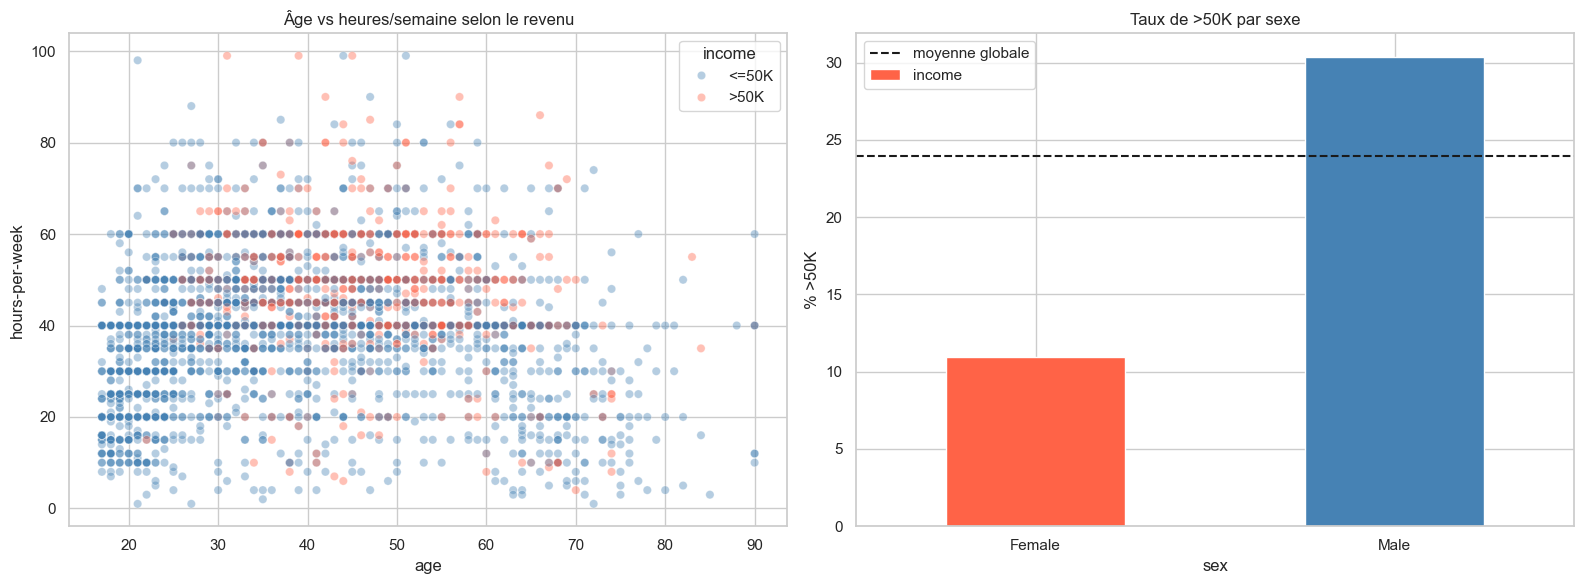

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Âge x heures travaillées, coloré par revenu
sns.scatterplot(
    data=df.sample(min(5000, len(df)), random_state=0),
    x="age", y="hours-per-week", hue=TARGET, alpha=0.4,
    palette={NEGATIVE_CLASS: "steelblue", POSITIVE_CLASS: "tomato"}, ax=axes[0],
)
axes[0].set_title("Âge vs heures/semaine selon le revenu")

# Taux >50K par sexe
sex_rate = df.groupby("sex")[TARGET].apply(lambda s: (s == POSITIVE_CLASS).mean() * 100)
sex_rate.plot(kind="bar", color=["tomato", "steelblue"], ax=axes[1], rot=0)
axes[1].axhline((y == POSITIVE_CLASS).mean() * 100, ls="--", color="k", label="moyenne globale")
axes[1].set_title("Taux de >50K par sexe")
axes[1].set_ylabel("% >50K")
axes[1].legend()

fig.tight_layout()
plt.show()

les points rouges (`>50K`) se concentrent dans la zone âge moyen + horaires pleins/élevés => Combinaison de facteurs, pas un seul.
Il y a un écart marqué de taux entre hommes et femmes vs la moyenne globale. Surement un reflet de biais sociétaux de 1994. et à surveiller
  côté **équité/biais** du modèle — utile pour une analyse de fairness ultérieure.

## 11. Importance des variables (information mutuelle)

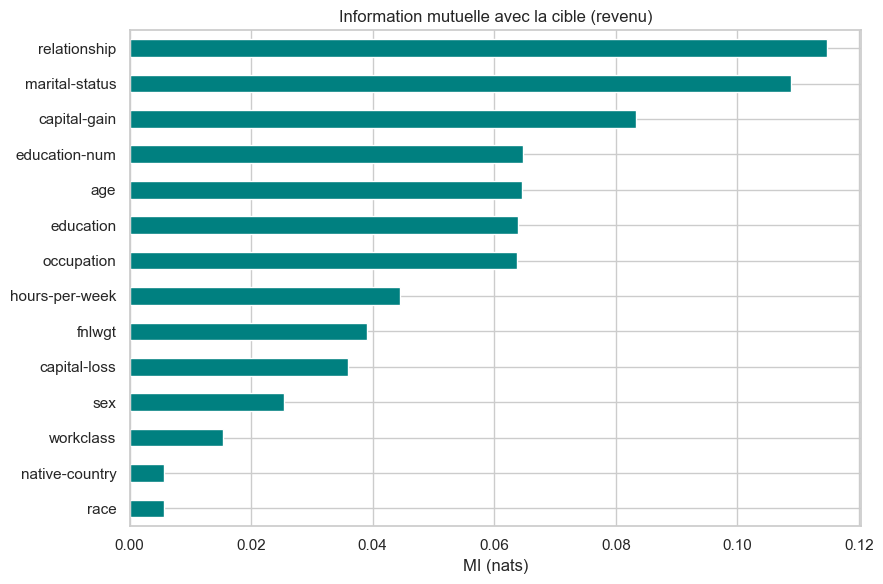

,mutual_info
relationship,0.114663
marital-status,0.108826
capital-gain,0.083236
education-num,0.064658
age,0.064549
education,0.063819
occupation,0.063672
hours-per-week,0.044528
fnlwgt,0.039022
capital-loss,0.036009


In [26]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

X_mi = X.copy()
for col in CATEGORICAL_FEATURES:
    X_mi[col] = LabelEncoder().fit_transform(X_mi[col].astype(str))

y_enc = (y == POSITIVE_CLASS).astype(int)
discrete_mask = [c in CATEGORICAL_FEATURES for c in X_mi.columns]

mi = mutual_info_classif(X_mi, y_enc, discrete_features=discrete_mask, random_state=42)
mi_s = pd.Series(mi, index=X_mi.columns).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(9, 6))
mi_s.plot(kind="barh", color="teal", ax=ax)
ax.invert_yaxis()
ax.set_title("Information mutuelle avec la cible (revenu)")
ax.set_xlabel("MI (nats)")
fig.tight_layout()
plt.show()
mi_s.to_frame("mutual_info")


L'information mutuelle mesure la dépendance (linéaire ou non) entre chaque variable et la cible — plus c'est haut, plus la variable est informative, sans présumer du modèle.
On retrouve en tête les variables identifiés comme significative plus tôt : `marital-status`, `relationship`, `education-num`,
  `capital-gain`, `age`, `hours-per-week`
Et on retrouve en bas `fnlwgt`, `race`, `native-country` qu'on avait identifié comme peu significative.
On doit ensuite prioriser le feature engineering sur les variables fortes et envisager d'écarter celles proches de 0 (ex. `fnlwgt`).



## 12. Synthèse & implications pour la modélisation

| Constat EDA | Décision modélisation |
|---|---|
| Classes déséquilibrées (~24 % `>50K`) | Métriques ROC-AUC/F1, split stratifié, `class_weight`/seuil |
| Manquants codés `'?'` (workclass, occupation, native-country) | Imputer ou catégorie « Unknown » dédiée |
| `capital-gain/loss` très asymétriques, pleins de 0 | log1p / binarisation ; scaler robuste |
| `fnlwgt` peu informatif (MI ≈ 0) | Candidat à la suppression |
| `education` ≈ `education-num` (redondance) | Garder une seule des deux |
| Catégorielles à forte cardinalité (`native-country`) | Regrouper modalités rares / target-encoding |
| Variables très prédictives : `marital-status`, `relationship`, `education`, `occupation`, `capital-gain`, `age`, `hours-per-week` | Cœur du modèle, soigner leur encodage |
| Écart de taux selon `sex`/`race` | Surveiller le biais / fairness |